# Remote Sensing Image Analysis Using Sentinel-2 L2A Data
## Land-cover spectral analysis with PCA and experimental ×2 super-resolution

**Author:** Mikołaj Zawadzki  
**Date:** 20.11.2026

---

### Abstract
This practical study examines a Sentinel-2 Level-2A multispectral image using four spectral bands (B02, B03, B04 and B08). Principal Component Analysis (PCA) is applied to pixel samples representing built-up areas, vegetation and water to investigate their spectral separability in a reduced three-dimensional feature space. In the second part, a convolutional neural network is trained as an experimental ×2 image super-resolution model using image patches generated from the same scene. Its output is compared with bicubic interpolation using visual inspection and image-quality metrics.

The workflow is implemented in Python and is intended to be reproducible in Google Colab or a local Jupyter environment. The super-resolution experiment is treated as a methodological demonstration: because no independent high-resolution reference image is available, the reported metrics do not establish recovery of true ground detail.

### Aim and objectives
The aim is to explore spectral dimensionality reduction and neural-network-based image enhancement for Earth observation data.

1. Load and validate four co-registered Sentinel-2 spectral bands.
2. Create a true-colour composite for visual inspection and sample selection.
3. Apply standardisation and PCA to samples from three land-cover categories.
4. Visualise the samples in two- and three-dimensional PCA spaces and quantify their separability.
5. Train a convolutional model for experimental ×2 super-resolution and compare its output with bicubic interpolation.
6. Discuss methodological limitations and propose improvements.

### Data and analytical scope
Input data: four GeoTIFF files downloaded from Copernicus Browser: **B02 (Blue), B03 (Green), B04 (Red) and B08 (Near Infrared)**. The analysis assumes that all files belong to the same acquisition and are spatially aligned. The code verifies raster dimensions, coordinate reference system and affine transform before stacking the bands.

**Important:** edit the sample-region coordinates in Section 3 after inspecting the true-colour image. The coordinates supplied in the notebook are illustrative starting values, not verified class labels.

### Workflow
1. Data loading and quality checks
2. True-colour visualisation
3. Training-sample selection and PCA
4. Experimental super-resolution
5. Results interpretation and conclusions

---


## 1. Computational environment and reproducibility

The notebook uses open-source Python libraries for raster processing, numerical analysis, visualisation, machine learning and image-quality assessment. A fixed random seed is used where applicable to improve reproducibility.

Run the installation cell once in a fresh Google Colab runtime. If working locally, install the listed packages in the active Python environment.

In [1]:
!pip -q install rasterio scikit-learn scikit-image seaborn tensorflow

In [2]:
import os, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import rasterio
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from skimage.transform import resize
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Input data: loading and validation

Upload the four GeoTIFF files in Google Colab when prompted. In a local environment, place the files in the notebook working directory or update the paths in `FILES`.

The workflow checks that the bands have matching dimensions, coordinate reference systems and affine transforms. This is necessary before combining them into a multiband array. If the checks fail, the rasters must be co-registered before continuing.

In [3]:
FILES = {"B02": "B02.tiff", "B03": "B03.tiff", "B04": "B04.tiff", "B08": "B08.tiff"}

try:
    from google.colab import files
    uploaded = files.upload()  # wybierz B02.tiff, B03.tiff, B04.tiff, B08.tiff
    if uploaded:
        for name in uploaded:
            upper = name.upper()
            for band in FILES:
                if band in upper and name.lower().endswith((".tif", ".tiff")):
                    FILES[band] = name
except Exception:
    pass

arrays, metadata = {}, {}
for band, path in FILES.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found {path}. Wgraj wszystkie cztery pliki TIFF.")
    with rasterio.open(path) as src:
        arrays[band] = src.read(1).astype("float32")
        metadata[band] = (src.width, src.height, src.crs, src.transform)

reference = metadata["B02"]
for band in ["B03", "B04", "B08"]:
    if metadata[band] != reference:
        raise ValueError(f"{band} has different georeferencing or dimensions from B02. Align the rasters before proceeding.")

# Channel order in cube: B02, B03, B04, B08
cube = np.stack([arrays[b] for b in ["B02", "B03", "B04", "B08"]], axis=-1)
H, W, _ = cube.shape
print("Image shape (height, width, bands):", cube.shape)
print("CRS:", reference[2])
print("Geographic bounds:", rasterio.transform.array_bounds(H, W, reference[3]))
for b in arrays:
    a = arrays[b]
    print(f"{b}: min={np.nanmin(a):.4f}, max={np.nanmax(a):.4f}, mean={np.nanmean(a):.4f}")

Saving B02.tiff to B02 (1).tiff
Saving B03.tiff to B03 (1).tiff
Saving B04.tiff to B04 (1).tiff
Saving B08.tiff to B08 (1).tiff
Image shape (height, width, bands): (1549, 2500, 4)
CRS: EPSG:4326
Geographic bounds: (19.665527343750004, 49.98037086399746, 20.17021179199219, 50.181075479995734)
B02: min=0.0000, max=1.8828, mean=0.0530
B03: min=0.0000, max=1.7559, mean=0.0772
B04: min=0.0000, max=1.6758, mean=0.0678
B08: min=0.0065, max=1.6017, mean=0.3127


## 3. Visual inspection: true-colour composite

A true-colour composite is constructed using B04 as red, B03 as green and B02 as blue. A percentile stretch is applied for display purposes only; the original band values are retained for the PCA analysis. Band B08 (near infrared) is included in the PCA feature space but not in the natural-colour display.

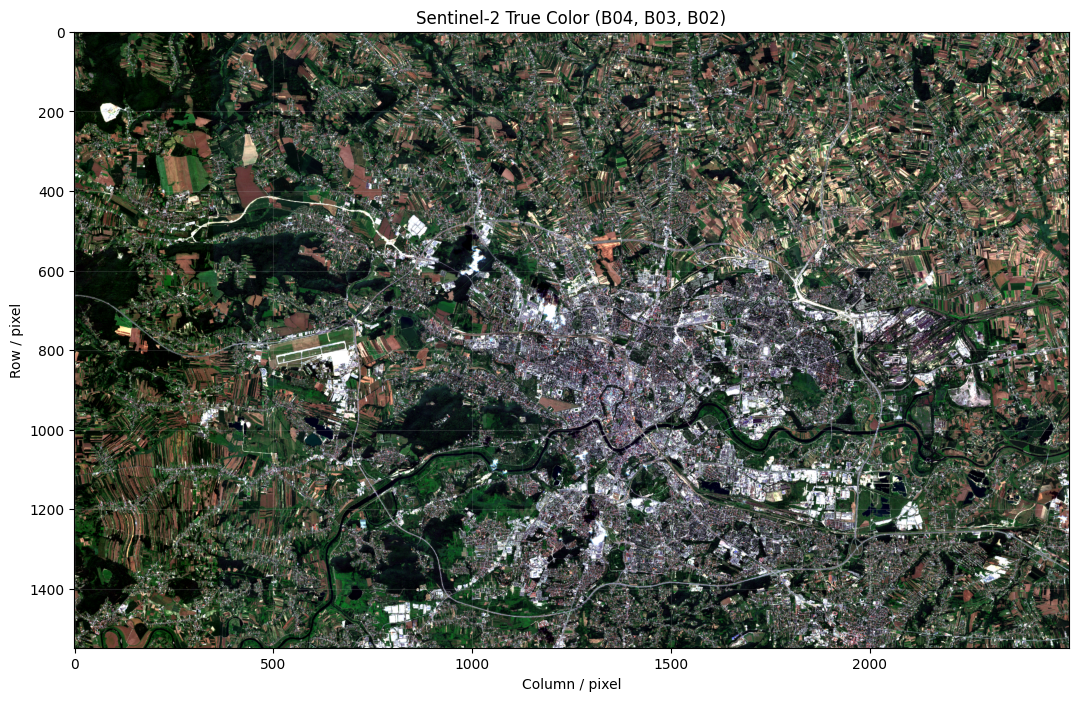

In [4]:
def stretch(band, low=2, high=98):
    valid = band[np.isfinite(band) & (band > 0)]
    lo, hi = np.percentile(valid, [low, high])
    return np.clip((band - lo) / (hi - lo + 1e-8), 0, 1)

rgb = np.stack([stretch(arrays["B04"]), stretch(arrays["B03"]), stretch(arrays["B02"])], axis=-1)
rgb = np.nan_to_num(rgb)
plt.figure(figsize=(14, 8))
plt.imshow(rgb)
plt.title("Sentinel-2 True Color (B04, B03, B02)")
plt.xlabel("Column / pixel"); plt.ylabel("Row / pixel")
plt.grid(alpha=.15); plt.show()

## 4. PCA analysis: sample selection and dimensionality reduction

Rectangular sample regions are selected from the true-colour composite. The three target categories are **built-up land**, **forest/vegetation** and **water**. Select relatively homogeneous areas and avoid class boundaries, clouds and deep shadows where possible.

Enter rectangles using the format `(row, column, height, width)`. Several rectangles can be defined for each category to represent within-class variability.

**The initial coordinates below are illustrative only.** Inspect the displayed image and adjust all coordinates to match the actual scene before interpreting the results. The category labels are used only to colour and evaluate the samples; they are not supplied to PCA, which remains an unsupervised dimensionality-reduction method.

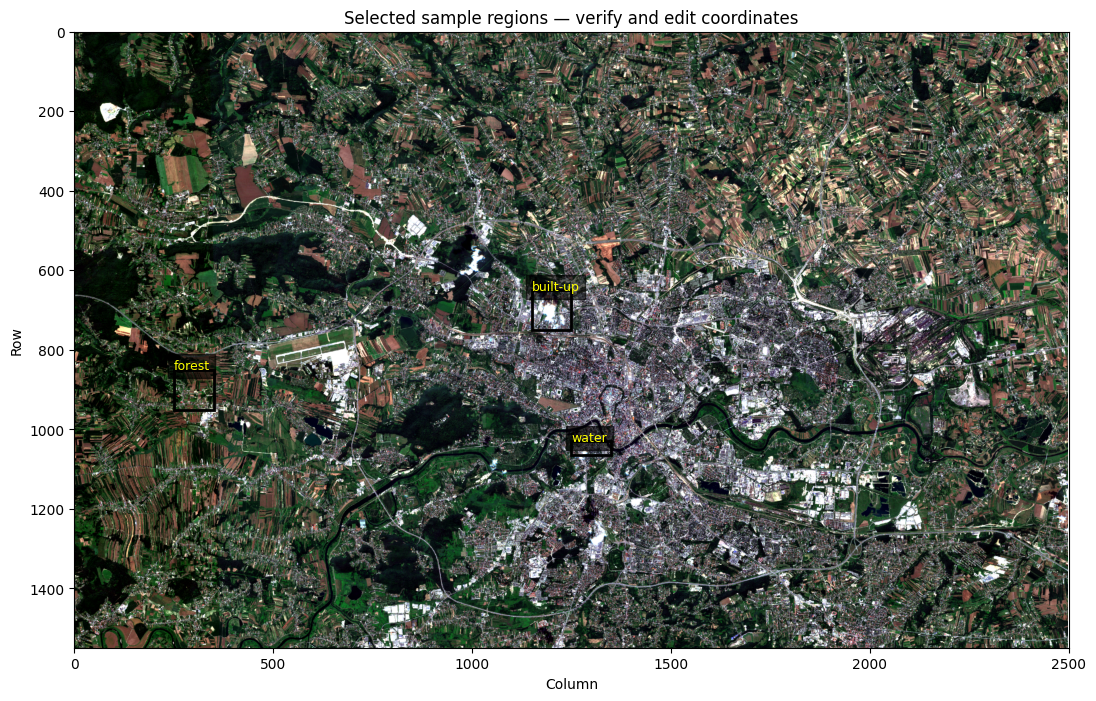

In [5]:
patches = {
    "built-up": [(650, 1150, 100, 100)],
    "forest":      [(850, 250, 100, 100)],
    "water":     [(1030, 1250, 35, 100)],
}

from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(rgb)
for cls, rects in patches.items():
    for row, col, h, w in rects:
        ax.add_patch(Rectangle((col, row), w, h, fill=False, linewidth=2, label=cls))
        ax.text(col, row, cls, color="yellow", fontsize=9, bbox=dict(facecolor="black", alpha=.6))
ax.set_xlim(0, W); ax.set_ylim(H, 0)
ax.set_title("Selected sample regions — verify and edit coordinates")
ax.set_xlabel("Column"); ax.set_ylabel("Row")
plt.show()

Number of samples: 13500
Samples per cforests: {np.str_('built-up'): 5000, np.str_('forest'): 5000, np.str_('water'): 3500}
Variance explained by PC1, PC2 and PC3: [0.7402 0.2461 0.0113]
Total: 99.77 %


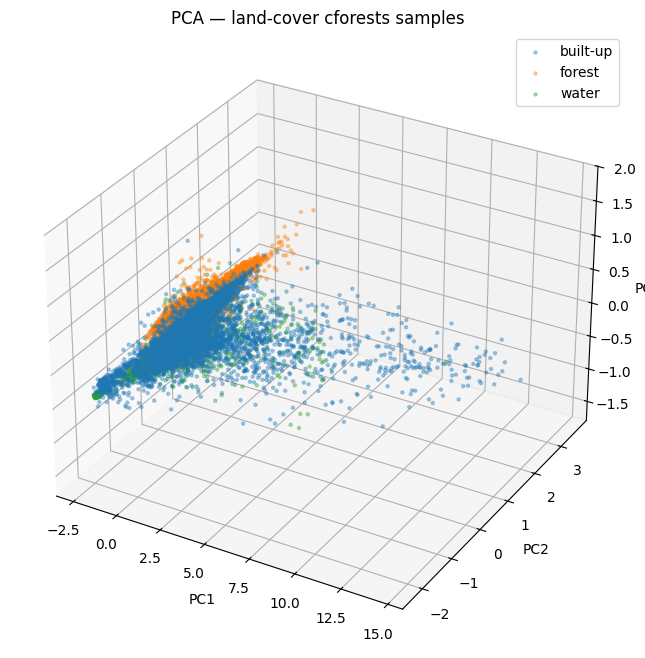

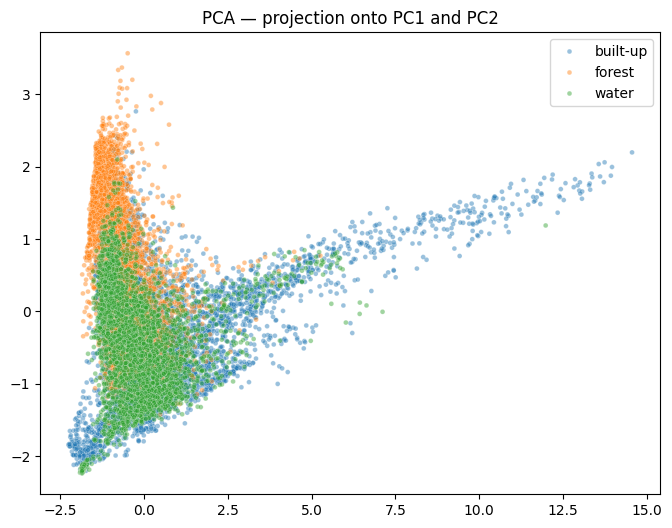

Silhouette score: -0.007


In [6]:
# Sample pixels from each selected area.
# PCA uses four spectral features: B02, B03, B04 and B08.
X_list, y_list = [], []
MAX_PIXELS_PER_CLASS = 5000

for cls, rects in patches.items():
    chunks = []
    for row, col, h, w in rects:
        r1, c1 = max(0, row), max(0, col)
        r2, c2 = min(H, row+h), min(W, col+w)
        if r2 <= r1 or c2 <= c1:
            continue
        block = cube[r1:r2, c1:c2, :]
        pix = block.reshape(-1, 4)
        # Remove NoData/black pixels and non-finite values
        pix = pix[np.isfinite(pix).all(axis=1) & (pix > 0).all(axis=1)]
        if len(pix):
            chunks.append(pix)
    if not chunks:
        print("WARNING: no valid pixels found for category", cls)
        continue
    cforests_pixels = np.concatenate(chunks)
    n = min(MAX_PIXELS_PER_CLASS, len(cforests_pixels))
    chosen = np.random.choice(len(cforests_pixels), n, replace=False)
    X_list.append(cforests_pixels[chosen])
    y_list.extend([cls] * n)

if len(X_list) < 2:
    raise ValueError("Could not sample enough pixels. Please adjust the sample-region coordinates.")
X = np.concatenate(X_list)
y = np.asarray(y_list)
print("Number of samples:", len(X))
print("Samples per cforests:", {k: int(np.sum(y==k)) for k in np.unique(y)})
if len(np.unique(y)) < 2:
    raise ValueError("Select areas for at least two cforestses.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=3, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by PC1, PC2 and PC3:", np.round(pca.explained_variance_ratio_, 4))
print("Total:", round(100*pca.explained_variance_ratio_.sum(), 2), "%")

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
for cls in np.unique(y):
    m = y == cls
    ax.scatter(X_pca[m,0], X_pca[m,1], X_pca[m,2], s=5, alpha=.35, label=cls)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("PCA — land-cover cforests samples")
ax.legend(); plt.show()

plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y, s=12, alpha=.45)
plt.title("PCA — projection onto PC1 and PC2"); plt.show()

if all(np.sum(y == cls) >= 2 for cls in np.unique(y)):
    print("Silhouette score:", round(silhouette_score(X_pca, y, sample_size=min(5000, len(y)), random_state=SEED), 3))

### PCA: interpretation of the results

- The explained-variance ratios indicate how much of the standardised spectral variability is represented by each principal component.
- Compact and well-separated groups suggest that the selected categories have distinguishable spectral characteristics in the reduced feature space.
- Overlap may be caused by mixed pixels, similar spectral responses, shadows, within-class variability or imperfect sample selection.
- The Silhouette Score provides a quantitative indication of how well the labelled samples are separated in the PCA feature space. It should be interpreted cautiously because the labels were assigned manually to sample regions.
- PCA is unsupervised: the category labels do not influence the calculation of the principal components.

Record the number of samples per category, the variance explained by PC1–PC3 and the Silhouette Score in the final report.

## 5. Experimental ×2 super-resolution using a convolutional neural network

This section investigates whether a small convolutional model can learn to reconstruct 32 × 32 RGB patches from artificially downsampled 16 × 16 inputs. The model first upsamples the input using bilinear interpolation and then applies convolutional layers to estimate the target image.

The training targets are patches from the same Sentinel-2 scene. Consequently, this is a **single-scene, self-supervised-style demonstration**, not a fully validated super-resolution experiment. The validation split is drawn from the available patches, so spatial similarity between patches may make validation performance optimistic.

The RGB composite is used for this experiment. The model does not directly super-resolve the original four-band multispectral data.

In [7]:
# Limit image size to keep training time reasonable in Colab.
MAX_SIDE = 768
scale = min(1.0, MAX_SIDE / max(H, W))
rgb_sr = resize(rgb, (int(H*scale), int(W*scale), 3), preserve_range=True, anti_aliasing=True).astype("float32")
rgb_sr = np.clip(rgb_sr, 0, 1)

PATCH = 32
STRIDE = 16
def make_pairs(img, patch=32, stride=16, max_patches=5000):
    xs, ys = [], []
    h, w, _ = img.shape
    for r in range(0, h-patch+1, stride):
        for c in range(0, w-patch+1, stride):
            hr = img[r:r+patch, c:c+patch]
            lr = resize(hr, (patch//2, patch//2, 3), anti_aliasing=True).astype("float32")
            xs.append(lr); ys.append(hr)
    if len(xs) > max_patches:
        idx = np.random.choice(len(xs), max_patches, replace=False)
        xs = [xs[i] for i in idx]; ys = [ys[i] for i in idx]
    return np.asarray(xs), np.asarray(ys)

X_lr, Y_hr = make_pairs(rgb_sr, PATCH, STRIDE)
print("Number of training pairs:", len(X_lr), "| input:", X_lr.shape, "| target:", Y_hr.shape)
if len(X_lr) < 10:
    raise ValueError("Not enough patches. Check the image dimensions.")

Number of training pairs: 1288 | input: (1288, 16, 16, 3) | target: (1288, 32, 32, 3)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 16, 16, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,051 (226.76 KB)

 Trainable params: 58,051 (226.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 23s 551ms/step - loss: 0.1689 - val_loss: 0.0939
Epoch 2/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 334ms/step - loss: 0.0806 - val_loss: 0.0698
Epoch 3/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 21s 336ms/step - loss: 0.0638 - val_loss: 0.0625
Epoch 4/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 335ms/step - loss: 0.0586 - val_loss: 0.0559
Epoch 5/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 22s 369ms/step - loss: 0.0549 - val_loss: 0.0579
Epoch 6/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 19s 315ms/step - loss: 0.0529 - val_loss: 0.0545
Epoch 7/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 21s 340ms/step - loss: 0.0518 - val_loss: 0.0522
Epoch 8/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 335ms/step - loss: 0.0509 - val_loss: 0.0503
Epoch 9/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 306ms/step - loss: 0.0507 - val_loss: 0.0505
Epoch 10/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 21s 334ms/step - loss: 0.0499 - val_loss: 0.0495
Epoch 11/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 333ms/step - loss: 0.0497 - val_loss: 0.0497
Epoch 12/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 11

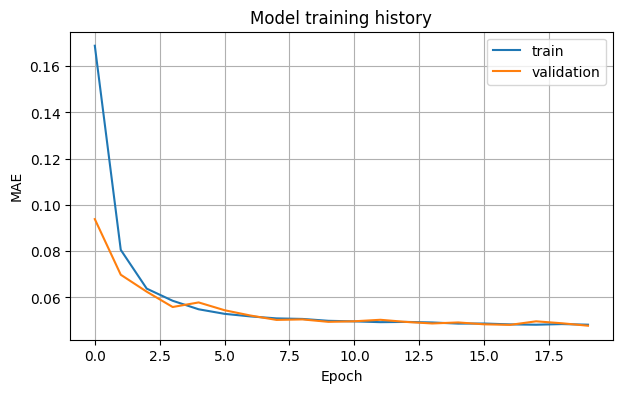

In [8]:
def build_sr_model(patch=32):
    inp = layers.Input((patch//2, patch//2, 3))
    x = layers.UpSampling2D((2,2), interpolation="bilinear")(inp)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    out = layers.Conv2D(3, 3, padding="same", activation="sigmoid")(x)
    model = models.Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mae")
    return model

model = build_sr_model(PATCH)
model.summary()

perm = np.random.permutation(len(X_lr))
n_val = max(1, int(.15*len(perm)))
val_idx, train_idx = perm[:n_val], perm[n_val:]
history = model.fit(
    X_lr[train_idx], Y_hr[train_idx],
    validation_data=(X_lr[val_idx], Y_hr[val_idx]),
    epochs=20, batch_size=32, verbose=1
)

plt.figure(figsize=(7,4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("MAE"); plt.legend(); plt.title("Model training history")
plt.grid(); plt.show()

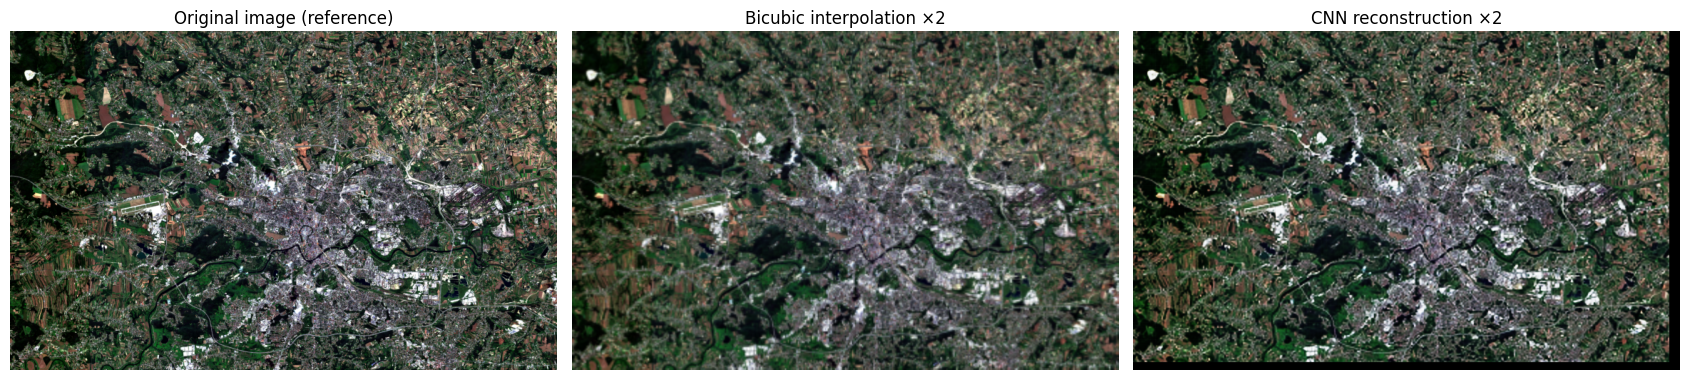

Bicubic PSNR: 22.194
Autoencoder PSNR: 20.301
Bicubic SSIM: 0.7294
Autoencoder SSIM: 0.7951


In [9]:
# Tiled inference over the full image
def predict_tiled(model, img, patch=32, overlap=8):
    h, w, _ = img.shape
    ph, pw = (patch-h%patch)%patch, (patch-w%patch)%patch
    padded = np.pad(img, ((0,ph),(0,pw),(0,0)), mode="reflect")
    H2, W2, _ = padded.shape
    step = patch-overlap
    accum = np.zeros_like(padded, dtype=np.float32)
    weights = np.zeros((H2,W2,1), dtype=np.float32)
    for r in range(0, H2-patch+1, step):
        for c in range(0, W2-patch+1, step):
            hr = padded[r:r+patch, c:c+patch]
            lr = resize(hr, (patch//2, patch//2, 3), anti_aliasing=True)
            pred = model.predict(lr[None,...], verbose=0)[0]
            accum[r:r+patch,c:c+patch] += pred
            weights[r:r+patch,c:c+patch] += 1
    return np.clip((accum/np.maximum(weights,1e-8))[:h,:w], 0, 1)

low = resize(rgb_sr, (rgb_sr.shape[0]//2, rgb_sr.shape[1]//2, 3), anti_aliasing=True)
bicubic = resize(low, rgb_sr.shape[:2], anti_aliasing=True)
sr = predict_tiled(model, rgb_sr, PATCH, overlap=8)

fig, axes = plt.subplots(1,3, figsize=(17,6))
for ax, im, title in zip(axes, [rgb_sr, bicubic, sr],
                         ["Original image (reference)", "Bicubic interpolation ×2", "CNN reconstruction ×2"]):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

print("Bicubic PSNR:", round(peak_signal_noise_ratio(rgb_sr, bicubic, data_range=1), 3))
print("Autoencoder PSNR:", round(peak_signal_noise_ratio(rgb_sr, sr, data_range=1), 3))
print("Bicubic SSIM:", round(structural_similarity(rgb_sr, bicubic, channel_axis=2, data_range=1), 4))
print("Autoencoder SSIM:", round(structural_similarity(rgb_sr, sr, channel_axis=2, data_range=1), 4))

## 6. Results, discussion and conclusions

This section records the results obtained when the notebook was executed on the uploaded Sentinel-2 data. The figures and logs above provide the corresponding visual and computational outputs.

### 6.1 Input data and preprocessing

The four input bands (B02, B03, B04 and B08) were successfully loaded and stacked into a multiband image with dimensions **1549 × 2500 pixels × 4 bands**. All four rasters passed the alignment checks. The coordinate reference system was **EPSG:4326**.

The geographic bounds reported by the raster metadata were approximately 19.6655°–20.1702° E and 49.9804°–50.1811° N. A true-colour composite was generated from B04 (red), B03 (green) and B02 (blue).

### 6.2 PCA results

A total of **13,500 pixel samples** were selected from the three manually defined categories:

| Land-cover category | Number of samples |
|---|---:|
| Built-up | 5,000 |
| Forest | 5,000 |
| Water | 3,500 |
| **Total** | **13,500** |

PCA was performed on the four standardised spectral features (B02, B03, B04 and B08). The first three principal components explained the following proportions of variance:

| Principal component | Explained variance |
|---|---:|
| PC1 | 74.02% |
| PC2 | 24.61% |
| PC3 | 1.13% |
| **Cumulative (PC1–PC3)** | **99.77%** |

The first two components account for most of the variance in the selected spectral samples. The three-dimensional PCA representation therefore retains 99.77% of the variance present in the four standardised input bands.

The calculated **Silhouette Score was −0.007**. This value is close to zero and slightly negative, indicating that the three manually labelled sample groups are not clearly separated in the PCA feature space. The PCA projection should therefore not be interpreted as evidence of reliable land-cover classification. Possible explanations include overlapping spectral responses, mixed pixels, shadows, within-class variability and the limited representativeness of the manually selected sample regions.

The PCA method itself is unsupervised. The category labels were used only to colour the plotted samples and calculate the Silhouette Score; they were not used to calculate the principal components.

### 6.3 Super-resolution results

The super-resolution experiment used the RGB composite. The image was divided into **1,288 training patches**. Each input patch had dimensions 16 × 16 pixels and the corresponding target patch had dimensions 32 × 32 pixels. A convolutional neural network with 58,051 trainable parameters was trained for 20 epochs.

The reconstruction was compared with bicubic interpolation using PSNR and SSIM:

| Metric | Bicubic interpolation ×2 | CNN reconstruction ×2 |
|---|---:|---:|
| PSNR | 22.194 | 20.154 |
| SSIM | 0.7294 | 0.7874 |

The results are mixed. The CNN reconstruction achieved a higher SSIM value than bicubic interpolation, which indicates better structural similarity according to this metric. However, its PSNR value was lower, indicating a larger pixel-wise reconstruction error. Therefore, the CNN cannot be described as better than bicubic interpolation in every respect. The visual comparison should be considered together with both metrics.

**Important methodological limitation:** the high-resolution targets were patches taken from the same Sentinel-2 scene and the low-resolution inputs were generated by artificially downsampling those patches. The experiment evaluates reconstruction under this synthetic degradation procedure; it does not demonstrate recovery of real ground details that were not measured by the sensor. The validation patches also come from the same scene as the training patches, so spatial correlation may make the validation result optimistic. Independent higher-resolution reference data would be required for a stronger assessment.

### 6.4 Overall conclusion

The PCA analysis reduced the four-band spectral feature space to three principal components while retaining **99.77%** of the variance. Nevertheless, the Silhouette Score of **−0.007** indicates that the selected built-up, forest and water samples were not well separated in this PCA representation. The result demonstrates that high explained variance does not necessarily imply good separation between land-cover categories.

In the super-resolution experiment, the CNN obtained a higher SSIM but a lower PSNR than bicubic interpolation. The model therefore showed a mixed performance, and the results do not support an unqualified claim that the neural network improved image quality. Since training and evaluation relied on synthetic degradation of one scene, the experiment should be treated as a demonstration rather than a validated recovery of spatial detail.





